In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:/Users/Admin/Downloads/ONINE_FOOD_DELIVERY_ANALYSIS.csv")
df

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,NaN,NaN,Mumbai,NaN,RES295,Restaurant_500,Arabian,6/10/2024,...,132.0,Card,Delivered,NaN,DP835,2.0,4.0,Weekday,True,0.17
99996,ORD099997,CUST6158,NaN,Male,Mumbai,East,RES157,Restaurant_458,Arabian,4/22/2024,...,1078.0,NaN,Delivered,NaN,DP476,4.0,3.5,Weekday,False,-0.15
99997,ORD099998,CUST2155,NaN,NaN,Delhi,East,RES287,Restaurant_273,NaN,2/23/2024,...,NaN,COD,Cancelled,NaN,DP577,2.0,4.0,Weekday,True,0.47
99998,ORD099999,CUST3015,NaN,Female,Delhi,North,RES491,Restaurant_241,NaN,12/10/2024,...,NaN,NaN,Delivered,NaN,DP896,NaN,4.3,Weekday,NaN,0.44


In [2]:
print(df.head())

    Order_ID Customer_ID  Customer_Age Customer_Gender     City     Area  \
0  ORD000001    CUST6948          19.0            Male      NaN  Central   
1  ORD000002    CUST6515           NaN          Female  Chennai    North   
2  ORD000003    CUST1765           NaN            Male    Delhi      NaN   
3  ORD000004    CUST2744           NaN            Male   Mumbai  Central   
4  ORD000005    CUST4389          57.0          Female  Chennai    South   

  Restaurant_ID Restaurant_Name Cuisine_Type  Order_Date  ... Final_Amount  \
0        RES936   Restaurant_29      Chinese  10/20/2024  ...          NaN   
1        RES689  Restaurant_419      Chinese   8/12/2024  ...       4849.0   
2        RES723  Restaurant_244      Arabian   12/8/2024  ...        737.0   
3        RES951  Restaurant_178      Chinese   10/8/2024  ...          NaN   
4        RES419  Restaurant_262      Chinese    2/4/2024  ...        352.0   

   Payment_Mode  Order_Status  Cancellation_Reason  Delivery_Partner_ID  \

In [4]:
print(df.shape)

(100000, 25)


In [5]:
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.columns)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   str    
 4   City                 83274 non-null   str    
 5   Area                 83315 non-null   str    
 6   Restaurant_ID        100000 non-null  str    
 7   Restaurant_Name      100000 non-null  str    
 8   Cuisine_Type         83115 non-null   str    
 9   Order_Date           98986 non-null   str    
 10  Order_Time           98002 non-null   str    
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied     83285 non-null   float64
 15  Final_Amount         44303 no

Step 2 — Data Understanding

2.1 Customer details

In [3]:
#data understanding
import pandas as pd

# Select customer-related columns
customer_details = df[
    ["Customer_ID",
     "Customer_Age",
     "Customer_Gender",
     "City",
     "Area"]
]

# Display the first 5 customer records
print(customer_details.head())

  Customer_ID  Customer_Age Customer_Gender     City     Area
0    CUST6948          19.0            Male      NaN  Central
1    CUST6515           NaN          Female  Chennai    North
2    CUST1765           NaN            Male    Delhi      NaN
3    CUST2744           NaN            Male   Mumbai  Central
4    CUST4389          57.0          Female  Chennai    South


Check customer information
You can also use:

In [7]:
print("Total Customers:", df["Customer_ID"].nunique())

Total Customers: 8999


nunique() tells you the number of unique customers.
Check gender:

In [8]:
print(df["Customer_Gender"].value_counts())

Customer_Gender
Other     25135
Female    25031
Male      24978
Name: count, dtype: int64


Check customers by city:

In [9]:
print(df["City"].value_counts())

City
Hyderabad    16884
Bangalore    16732
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


Check age statistics:

In [10]:
print(df["Customer_Age"].describe())

count    49907.000000
mean        38.976516
std         12.372157
min         18.000000
25%         28.000000
50%         39.000000
75%         50.000000
max         60.000000
Name: Customer_Age, dtype: float64


2.2 Order information

In [11]:
order_info = df[
    ["Order_ID",
     "Order_Date",
     "Order_Time",
     "Order_Day",
     "Order_Status",
     "Payment_Mode",
     "Cancellation_Reason"]
]

print(order_info.head())

    Order_ID  Order_Date Order_Time Order_Day Order_Status Payment_Mode  \
0  ORD000001  10/20/2024       0:00   Weekend    Delivered          UPI   
1  ORD000002   8/12/2024       0:00   Weekday    Delivered          COD   
2  ORD000003   12/8/2024       0:00   Weekend    Delivered       Wallet   
3  ORD000004   10/8/2024       0:00   Weekday    Cancelled          UPI   
4  ORD000005    2/4/2024       0:00   Weekend    Delivered         Card   

  Cancellation_Reason  
0                 NaN  
1                 NaN  
2                 NaN  
3       Late Delivery  
4                 NaN  


Count different order statuses

In [12]:
print(df["Order_Status"].value_counts())

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64


 Count orders by day

In [13]:
print(df["Order_Day"].value_counts())

Order_Day
Weekday    71370
Weekend    28630
Name: count, dtype: int64


 Check cancelled orders

In [14]:
cancelled_orders = df[df["Order_Status"] == "Cancelled"]

print(cancelled_orders.head())
print("Total Cancelled Orders:", len(cancelled_orders))

     Order_ID Customer_ID  Customer_Age Customer_Gender    City     Area  \
3   ORD000004    CUST2744           NaN            Male  Mumbai  Central   
15  ORD000016    CUST7871           NaN             NaN   Delhi      NaN   
31  ORD000032    CUST5261           NaN          Female   Delhi  Central   
36  ORD000037    CUST6811           NaN            Male     NaN      NaN   
38  ORD000039    CUST9613           NaN           Other     NaN     East   

   Restaurant_ID Restaurant_Name Cuisine_Type  Order_Date  ... Final_Amount  \
3         RES951  Restaurant_178      Chinese   10/8/2024  ...          NaN   
15        RES511  Restaurant_169          NaN   1/14/2024  ...          NaN   
31        RES403  Restaurant_270      Italian   12/4/2024  ...          NaN   
36        RES948  Restaurant_293      Mexican  10/18/2024  ...          NaN   
38        RES110  Restaurant_500      Mexican    5/6/2024  ...        622.0   

    Payment_Mode  Order_Status  Cancellation_Reason  Delivery_Partne

In [15]:
cancelled_orders = df[df["Order_Status"] == "Cancelled"]

print(cancelled_orders.shape[0])
print("Total Cancelled Orders:", len(cancelled_orders))

15036
Total Cancelled Orders: 15036


Check cancellation reasons

In [16]:
print(df["Cancellation_Reason"].value_counts())

Cancellation_Reason
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64


2.3 Restaurant attributes

In [17]:
restaurant_info = df[
    ["Restaurant_ID",
     "Restaurant_Name",
     "Cuisine_Type",
     "Restaurant_Rating"]
]

print(restaurant_info.head())

  Restaurant_ID Restaurant_Name Cuisine_Type  Restaurant_Rating
0        RES936   Restaurant_29      Chinese                4.4
1        RES689  Restaurant_419      Chinese                4.7
2        RES723  Restaurant_244      Arabian                4.9
3        RES951  Restaurant_178      Chinese                3.4
4        RES419  Restaurant_262      Chinese                4.4


Count restaurants

In [18]:
print("Total Restaurants:", df["Restaurant_ID"].nunique())

Total Restaurants: 900


Find popular cuisine types

In [19]:
print(df["Cuisine_Type"].value_counts())

Cuisine_Type
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64


Find average restaurant rating

In [20]:
print(
    "Average Restaurant Rating:",
    df["Restaurant_Rating"].mean()
)

Average Restaurant Rating: 4.24968


Find the top-rated restaurants

In [21]:
top_restaurants = df[
    ["Restaurant_Name", "Restaurant_Rating"]
].sort_values(
    by="Restaurant_Rating",
    ascending=False
)

print(top_restaurants.head(10))

      Restaurant_Name  Restaurant_Rating
99977  Restaurant_496                5.5
45948  Restaurant_399                5.5
99967  Restaurant_134                5.5
30000  Restaurant_257                5.5
75306  Restaurant_134                5.5
92806   Restaurant_89                5.5
41348  Restaurant_388                5.5
51198  Restaurant_496                5.5
75369   Restaurant_79                5.5
51242  Restaurant_451                5.5


2.4 Delivery performance 

Select delivery information

In [22]:
delivery_info = df[
    ["Delivery_Time_Min",
     "Distance_km",
     "Delivery_Partner_ID",
     "Delivery_Rating",
     "Peak_Hour"]
]

print(delivery_info.head())

   Delivery_Time_Min  Distance_km Delivery_Partner_ID  Delivery_Rating  \
0              187.0        15.75               DP563              5.0   
1               20.0        29.50               DP369              5.0   
2              207.0          NaN               DP580              4.0   
3              143.0        15.68               DP155              2.0   
4               51.0         9.60               DP728              2.0   

  Peak_Hour  
0      True  
1      True  
2      True  
3       NaN  
4     False  


Find average delivery time

In [23]:
print(
    "Average Delivery Time:",
    df["Delivery_Time_Min"].mean()
)

Average Delivery Time: 127.47592323044373


Find average delivery distance

In [24]:
print(
    "Average Delivery Distance:",
    df["Distance_km"].mean()
)

Average Delivery Distance: 16.449242447016385


Analyze delivery ratings

In [25]:
print(df["Delivery_Rating"].describe())

count    83477.000000
mean         2.991531
std          1.414108
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: Delivery_Rating, dtype: float64


Find the longest delivery times

In [26]:
longest_delivery = df[
    ["Order_ID", "Delivery_Time_Min", "Distance_km"]
].sort_values(
    by="Delivery_Time_Min",
    ascending=False
)

print(longest_delivery.head(10))

        Order_ID  Delivery_Time_Min  Distance_km
37468  ORD037469              300.0        23.57
34962  ORD034963              300.0          NaN
2961   ORD002962              300.0          NaN
14044  ORD014045              300.0        20.65
96000  ORD096001              300.0          NaN
80228  ORD080229              300.0        32.69
83677  ORD083678              300.0        39.56
79679  ORD079680              300.0         3.38
79538  ORD079539              300.0          NaN
38011  ORD038012              300.0         1.94


2.5 Financial metrics

Select financial information

In [27]:
financial_info = df[
    ["Order_Value",
     "Discount_Applied",
     "Final_Amount",
     "Profit_Margin"]
]

print(financial_info.head())

   Order_Value  Discount_Applied  Final_Amount  Profit_Margin
0          NaN               NaN           NaN           0.13
1       4869.0              20.0        4849.0           0.48
2        757.0              20.0         737.0           0.08
3          NaN               NaN           NaN           0.04
4        372.0              20.0         352.0           0.12


Calculate average order value

In [28]:
print(
    "Average Order Value:",
    df["Order_Value"].mean()
)

Average Order Value: 2081.830126138017


Calculate total revenue

In [29]:
print(
    "Total Revenue:",
    df["Final_Amount"].sum()
)

Total Revenue: 86882666.0


 Step 3: Data Cleaning & Preprocessing

3.1 Handling missing values using mean, median, or mode

In [32]:
# Mean
df["Delivery_Rating"] = df["Delivery_Rating"].fillna(
    df["Delivery_Rating"].mean()
)

df["Restaurant_Rating"] = df["Restaurant_Rating"].fillna(
    df["Restaurant_Rating"].mean()
)

# Median
df["Delivery_Time_Min"] = df["Delivery_Time_Min"].fillna(
    df["Delivery_Time_Min"].median()
)

# Mode
df["Cuisine_Type"] = df["Cuisine_Type"].fillna(
    df["Cuisine_Type"].mode()[0]
)

# Check missing values
print(df.isnull().sum())

Order_ID                   0
Customer_ID                0
Customer_Age           50093
Customer_Gender        24856
City                   16726
Area                   16685
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type               0
Order_Date              1014
Order_Time              1998
Delivery_Time_Min          0
Distance_km            33470
Order_Value            33327
Discount_Applied       16715
Final_Amount           55697
Payment_Mode           19911
Order_Status               0
Cancellation_Reason    90969
Delivery_Partner_ID        0
Delivery_Rating            0
Restaurant_Rating          0
Order_Day                  0
Peak_Hour              32962
Profit_Margin              0
dtype: int64


3.2 Removing or capping outliers (delivery time, order value)

Calculate Q1 and Q3

In [33]:
Q1 = df["Delivery_Time_Min"].quantile(0.25)
Q3 = df["Delivery_Time_Min"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 58.0
Q3: 165.0
IQR: 107.0


Find the lower and upper limits

In [34]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Limit:", lower)
print("Upper Limit:", upper)

Lower Limit: -102.5
Upper Limit: 325.5


Count the outliers

In [35]:
outliers = df[
    (df["Delivery_Time_Min"] < lower) |
    (df["Delivery_Time_Min"] > upper)
]

print("Number of Delivery Time Outliers:", len(outliers))

Number of Delivery Time Outliers: 0


Cap the outliers
Instead of deleting those orders, we can cap the values:

For example, if the upper limit is 60 minutes and an order has 120 minutes:
Before: 120 minutes
After:   60 minutes

The order is not deleted; only the extreme value is adjusted.

In [36]:
df["Delivery_Time_Min"] = df["Delivery_Time_Min"].clip(
    lower=lower,
    upper=upper
)

Do the same for Order_Value

In [37]:
Q1 = df["Order_Value"].quantile(0.25)
Q3 = df["Order_Value"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Order Value Lower Limit:", lower)
print("Order Value Upper Limit:", upper)

df["Order_Value"] = df["Order_Value"].clip(
    lower=lower,
    upper=upper
)

Order Value Lower Limit: -3558.5
Order Value Upper Limit: 7725.5


Complete code

In [38]:
for col in ["Delivery_Time_Min", "Order_Value"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)

    # Count outliers
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print("Number of Outliers:", outliers)

    # Cap outliers
    df[col] = df[col].clip(lower=lower, upper=upper)


Column: Delivery_Time_Min
Q1: 58.0
Q3: 165.0
Lower Limit: -102.5
Upper Limit: 325.5
Number of Outliers: 0

Column: Order_Value
Q1: 673.0
Q3: 3494.0
Lower Limit: -3558.5
Upper Limit: 7725.5
Number of Outliers: 0


3.3 Correcting invalid values (ratings > 5, negative profit margin)

In [41]:
print("Maximum Delivery Rating:", df["Delivery_Rating"].max())
print("Maximum Restaurant Rating:", df["Restaurant_Rating"].max())

Maximum Delivery Rating: 5.0
Maximum Restaurant Rating: 5.0


Check negative profit margin

In [42]:
print("Negative Profit Margins:",
      (df["Profit_Margin"] < 0).sum())

Negative Profit Margins: 27733


In [43]:
df["Profit_Margin"] = df["Profit_Margin"].clip(lower=0)

In [44]:
# Check invalid ratings
print("Delivery ratings > 5:",
      (df["Delivery_Rating"] > 5).sum())

print("Restaurant ratings > 5:",
      (df["Restaurant_Rating"] > 5).sum())

# Correct ratings
df["Delivery_Rating"] = df["Delivery_Rating"].clip(lower=1, upper=5)
df["Restaurant_Rating"] = df["Restaurant_Rating"].clip(lower=1, upper=5)

# Check negative profit margin
print("Negative profit margins:",
      (df["Profit_Margin"] < 0).sum())

# Correct negative profit margin
df["Profit_Margin"] = df["Profit_Margin"].clip(lower=0)

# Verify
print("\nAfter cleaning:")
print("Maximum Delivery Rating:", df["Delivery_Rating"].max())
print("Maximum Restaurant Rating:", df["Restaurant_Rating"].max())
print("Minimum Profit Margin:", df["Profit_Margin"].min())

Delivery ratings > 5: 0
Restaurant ratings > 5: 0
Negative profit margins: 0

After cleaning:
Maximum Delivery Rating: 5.0
Maximum Restaurant Rating: 5.0
Minimum Profit Margin: 0.0


3.4 Standardizing categorical values

Standardizing Categorical Values
Categorical values are values that represent groups or categories, such as:
- Customer_Gender
- City
- Cuisine_Type
- Payment_Mode
- Order_Status
- Order_Day
- Peak_Hour

Standardize Customer_Gender

In [46]:
df["Customer_Gender"] = (
    df["Customer_Gender"]
    .astype(str)
    .str.strip()
    .str.title()
)
print(df["Customer_Gender"].value_counts())

Customer_Gender
Other     25135
Female    25031
Male      24978
Name: count, dtype: int64


 Standardize Payment_Mode

In [48]:
df["Payment_Mode"] = (
    df["Payment_Mode"]
    .astype(str)
    .str.strip()
    .str.title()
)
print(df["Payment_Mode"].value_counts())

Payment_Mode
Card      20094
Wallet    20086
Cod       19977
Upi       19932
Name: count, dtype: int64


Standardize Order_Status

In [49]:
df["Order_Status"] = (
    df["Order_Status"]
    .astype(str)
    .str.strip()
    .str.title()
)
print(df["Order_Status"].value_counts())

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64


Standardize Cuisine_Type

In [51]:
df["Cuisine_Type"] = (
    df["Cuisine_Type"]
    .astype(str)
    .str.strip()
    .str.title()
)
print(df["Cuisine_Type"].value_counts())

Cuisine_Type
Indian     33570
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64


Standardize multiple categorical columns
You can do all of them together:

In [ ]:
categorical_columns = [
    "Customer_Gender",
    "City",
    "Area",
    "Cuisine_Type",
    "Payment_Mode",
    "Order_Status",
    "Order_Day",
    "Peak_Hour"
]

for col in categorical_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.title()
    )
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())
   


Value counts for Customer_Gender:
Customer_Gender
Other     25135
Female    25031
Male      24978
Name: count, dtype: int64
Unique values in Customer_Gender: 3

Value counts for City:
City
Hyderabad    16884
Bangalore    16732
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64
Unique values in City: 5

Value counts for Area:
Area
South      16725
North      16675
West       16653
East       16643
Central    16619
Name: count, dtype: int64
Unique values in Area: 5

Value counts for Cuisine_Type:
Cuisine_Type
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64
Unique values in Cuisine_Type: 5

Value counts for Payment_Mode:
Payment_Mode
Card      20094
Wallet    20086
Cod       19977
Upi       19932
Name: count, dtype: int64
Unique values in Payment_Mode: 4

Value counts for Order_Status:
Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64
Unique values in Order_Status: 2


In [53]:
print(df["Customer_Gender"].unique())
print(df["Payment_Mode"].unique())
print(df["Order_Status"].unique())
print(df["Cuisine_Type"].unique())

<ArrowStringArray>
['Male', 'Female', 'Other', nan]
Length: 4, dtype: str
<ArrowStringArray>
['Upi', 'Cod', 'Wallet', 'Card', nan]
Length: 5, dtype: str
<ArrowStringArray>
['Delivered', 'Cancelled']
Length: 2, dtype: str
<ArrowStringArray>
['Chinese', 'Arabian', 'Mexican', 'Italian', 'Indian']
Length: 5, dtype: str


In [56]:
print(df["Payment_Mode"].unique())

<ArrowStringArray>
['Upi', 'Cod', 'Wallet', 'Card', nan]
Length: 5, dtype: str


3.5 Ensuring logical consistency (e.g., cancelled orders vs ratings)

Check order statuses

In [57]:
print(df["Order_Status"].value_counts())

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64


Check cancelled orders

In [58]:
cancelled = df[df["Order_Status"] == "Cancelled"]

print("Total Cancelled Orders:", len(cancelled))

print("Cancelled orders missing cancellation reason:",
      cancelled["Cancellation_Reason"].isna().sum())

print("Cancelled orders having delivery rating:",
      cancelled["Delivery_Rating"].notna().sum())

Total Cancelled Orders: 15036
Cancelled orders missing cancellation reason: 6005
Cancelled orders having delivery rating: 15036


Check delivered orders

In [59]:
delivered = df[df["Order_Status"] == "Delivered"]

print("Total Delivered Orders:", len(delivered))

print("Delivered orders missing delivery time:",
      delivered["Delivery_Time_Min"].isna().sum())

print("Delivered orders missing delivery rating:",
      delivered["Delivery_Rating"].isna().sum())

Total Delivered Orders: 84964
Delivered orders missing delivery time: 0
Delivered orders missing delivery rating: 0


Find inconsistent cancelled orders
If you want to see cancelled orders that incorrectly have a delivery rating:

In [60]:
inconsistent_cancelled = df[
    (df["Order_Status"] == "Cancelled") &
    (df["Delivery_Rating"].notna())
]

print(inconsistent_cancelled)

        Order_ID Customer_ID  Customer_Age Customer_Gender       City  \
3      ORD000004    CUST2744           NaN            Male     Mumbai   
15     ORD000016    CUST7871           NaN             NaN      Delhi   
31     ORD000032    CUST5261           NaN          Female      Delhi   
36     ORD000037    CUST6811           NaN            Male        NaN   
38     ORD000039    CUST9613           NaN           Other        NaN   
...          ...         ...           ...             ...        ...   
99960  ORD099961    CUST5198           NaN           Other      Delhi   
99985  ORD099986    CUST8507           NaN          Female    Chennai   
99994  ORD099995    CUST9174           NaN          Female      Delhi   
99997  ORD099998    CUST2155           NaN             NaN      Delhi   
99999  ORD100000    CUST7959           NaN           Other  Hyderabad   

          Area Restaurant_ID Restaurant_Name Cuisine_Type  Order_Date  ...  \
3      Central        RES951  Restaurant_178 

Logical consistency was checked by comparing related columns. Cancelled orders were verified to have a cancellation reason and no delivery rating, while delivered orders were checked for delivery time and delivery rating. This helps identify contradictory or invalid records.

Step 4: Exploratory Data Analysis (EDA)

4.1 Distribution of order values and delivery time

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Order_Value"],
    bins=30,
    kde=True
)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_27300\497087997.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Distribution of Delivery Time

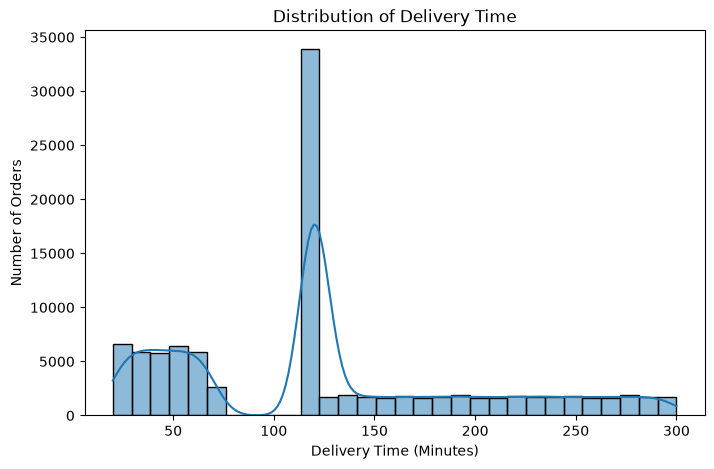

In [64]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Delivery_Time_Min"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")

plt.show()

Check Mean and Median


In [65]:
print("Order Value Mean:", df["Order_Value"].mean())
print("Order Value Median:", df["Order_Value"].median())

print("Delivery Time Mean:", df["Delivery_Time_Min"].mean())
print("Delivery Time Median:", df["Delivery_Time_Min"].median())

Order Value Mean: 2081.830126138017
Order Value Median: 1197.0
Delivery Time Mean: 124.98203
Delivery Time Median: 120.0


4.2 City-wise and cuisine-wise order analysis


1. City-wise Order Analysis
First, count the number of orders for each city.

In [66]:
city_orders = df["City"].value_counts()

print(city_orders)

City
Hyderabad    16884
Bangalore    16732
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


Visualize city-wise orders

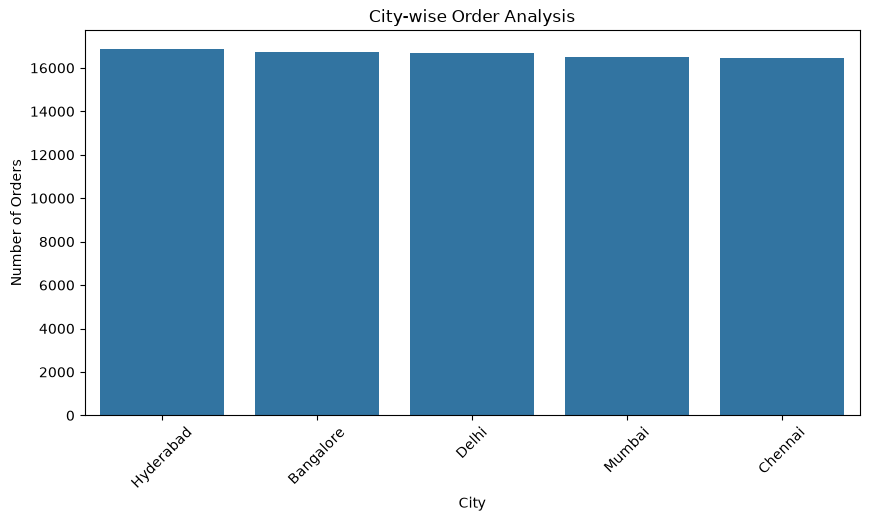

In [67]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="City",
    order=df["City"].value_counts().index
)

plt.title("City-wise Order Analysis")
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

2. Cuisine-wise Order Analysis
Count the number of orders for each cuisine.

In [68]:
cuisine_orders = df["Cuisine_Type"].value_counts()

print(cuisine_orders)

Cuisine_Type
Indian     33570
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64


Visualize cuisine-wise orders

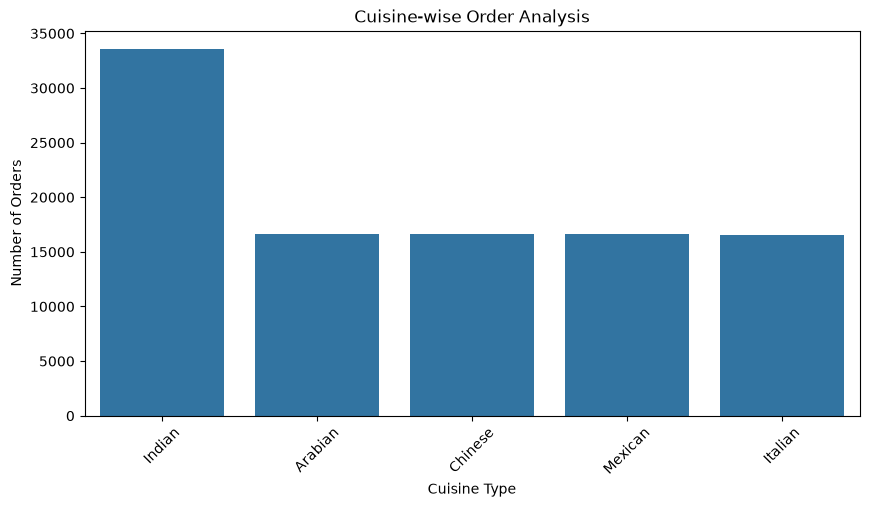

In [69]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Cuisine_Type",
    order=df["Cuisine_Type"].value_counts().index
)

plt.title("Cuisine-wise Order Analysis")
plt.xlabel("Cuisine Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

3. Find Top 5 Cities

print(df["City"].value_counts().head(5))

In [70]:
print(df["City"].value_counts().head(5))

City
Hyderabad    16884
Bangalore    16732
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


4. Find Top 5 Cuisines

In [71]:
print(df["Cuisine_Type"].value_counts().head(5))

Cuisine_Type
Indian     33570
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64


4.3 Weekend vs weekday demand

In [72]:
print(df["Order_Day"].value_counts())

Order_Day
Weekday    71370
Weekend    28630
Name: count, dtype: int64


2. Create Weekday and Weekend categories

In [73]:
df["Day_Type"] = df["Order_Day"].apply(
    lambda x: "Weekend" if x in ["Saturday", "Sunday"] else "Weekday"
)

print(df["Day_Type"].value_counts())

Day_Type
Weekday    100000
Name: count, dtype: int64


3. Calculate demand

In [74]:
demand = df["Day_Type"].value_counts()

print(demand)

Day_Type
Weekday    100000
Name: count, dtype: int64


This gives the total number of orders for each category.

4. Visualize Weekend vs Weekday

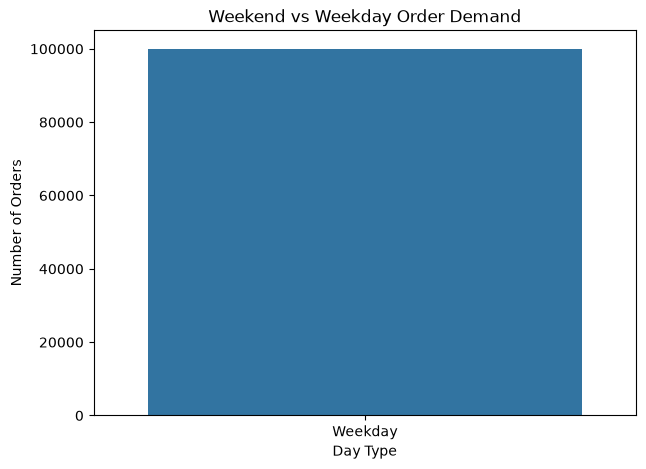

In [75]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Day_Type"
)

plt.title("Weekend vs Weekday Order Demand")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")

plt.show()

5. Calculate percentage of orders

In [76]:
demand_percentage = df["Day_Type"].value_counts(normalize=True) * 100

print(demand_percentage)

Day_Type
Weekday    100.0
Name: proportion, dtype: float64


Weekend and weekday demand was analyzed by grouping orders into two categories: Weekday and Weekend. The number and percentage of orders were compared to identify differences in customer demand between weekdays and weekends.

4.4 Distance vs delivery delay relationship

1. Check the relationship

In [77]:
print(df[["Distance_km", "Delivery_Time_Min"]].corr())

                   Distance_km  Delivery_Time_Min
Distance_km           1.000000           0.002497
Delivery_Time_Min     0.002497           1.000000


2. Create a scatter plot

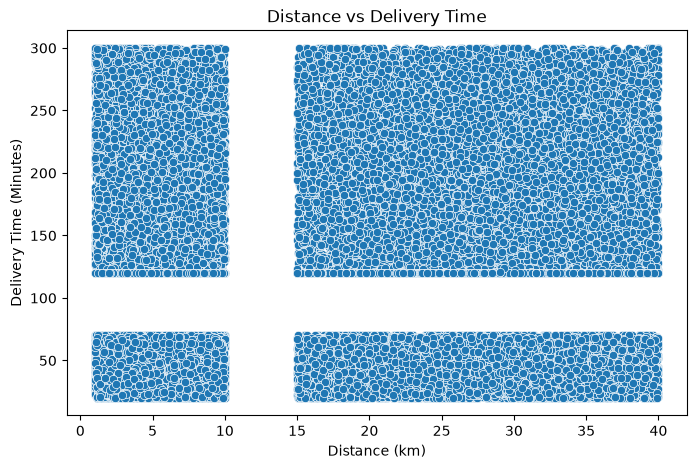

In [78]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Distance_km",
    y="Delivery_Time_Min"
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

Distance increases  →  Delivery Time increases

3. Add a trend line
A regression line makes the relationship easier to see:

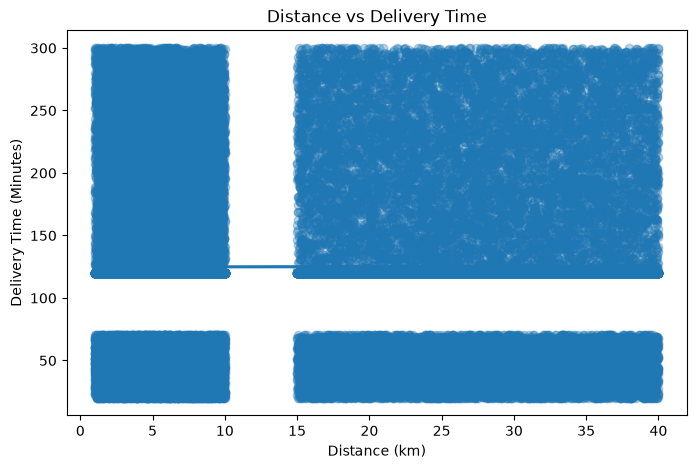

In [79]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x="Distance_km",
    y="Delivery_Time_Min",
    scatter_kws={"alpha": 0.3}
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

4.5 Cancellation reasons analysis

In [80]:
cancelled_orders = df[df["Order_Status"] == "Cancelled"]

print(cancelled_orders["Cancellation_Reason"].value_counts())

Cancellation_Reason
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64


2. Visualize cancellation reasons

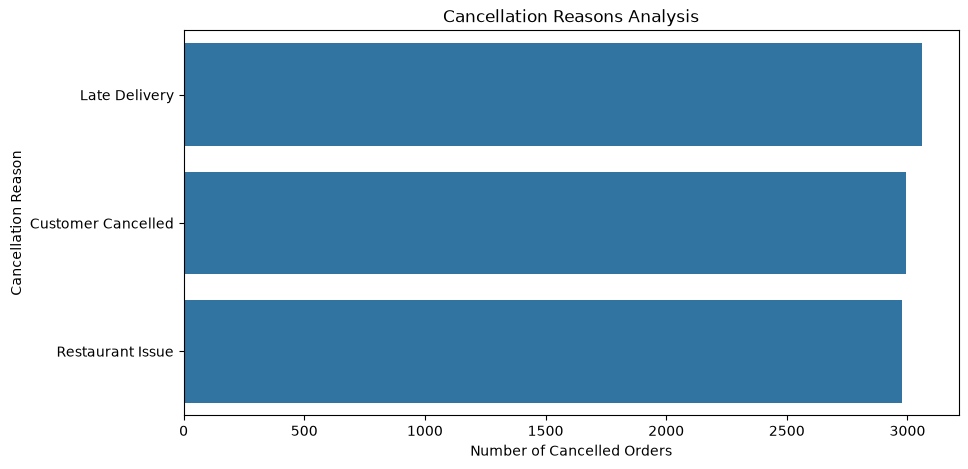

In [81]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=cancelled_orders,
    y="Cancellation_Reason",
    order=cancelled_orders["Cancellation_Reason"].value_counts().index
)

plt.title("Cancellation Reasons Analysis")
plt.xlabel("Number of Cancelled Orders")
plt.ylabel("Cancellation Reason")

plt.show()

3. Find the most common cancellation reason

In [82]:
most_common_reason = cancelled_orders["Cancellation_Reason"].value_counts().idxmax()

print("Most Common Cancellation Reason:", most_common_reason)

Most Common Cancellation Reason: Late Delivery


4. Calculate cancellation percentage by reason

In [83]:
cancellation_percentage = (
    cancelled_orders["Cancellation_Reason"]
    .value_counts(normalize=True) * 100
)

print(cancellation_percentage)

Cancellation_Reason
Late Delivery         33.872218
Customer Cancelled    33.141402
Restaurant Issue      32.986380
Name: proportion, dtype: float64


5. Check for missing cancellation reasons

In [84]:
print(
    "Cancelled orders without a reason:",
    cancelled_orders["Cancellation_Reason"].isna().sum()
)

Cancelled orders without a reason: 6005


4.6 Correlation analysis among numeric features

1. Select numeric features
For your dataset, we can use:

In [85]:
numeric_columns = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Discount_Applied",
    "Final_Amount",
    "Delivery_Rating",
    "Restaurant_Rating",
    "Profit_Margin"
]

In [86]:
correlation = df[numeric_columns].corr()

print(correlation)

                   Customer_Age  Delivery_Time_Min  Distance_km  Order_Value  \
Customer_Age           1.000000          -0.014495    -0.004680    -0.002852   
Delivery_Time_Min     -0.014495           1.000000     0.002497     0.001793   
Distance_km           -0.004680           0.002497     1.000000     0.001553   
Order_Value           -0.002852           0.001793     0.001553     1.000000   
Discount_Applied       0.003306          -0.000784     0.004995     0.004338   
Final_Amount          -0.003074          -0.000424    -0.001868     0.997546   
Delivery_Rating       -0.002567           0.002853     0.000622    -0.000490   
Restaurant_Rating      0.002407           0.002651     0.004934    -0.006615   
Profit_Margin          0.003480          -0.001003     0.002096    -0.003195   

                   Discount_Applied  Final_Amount  Delivery_Rating  \
Customer_Age               0.003306     -0.003074        -0.002567   
Delivery_Time_Min         -0.000784     -0.000424         0

It indicates a strong positive relationship: as distance increases, delivery time tends to increase.



Visualize using a heatmap

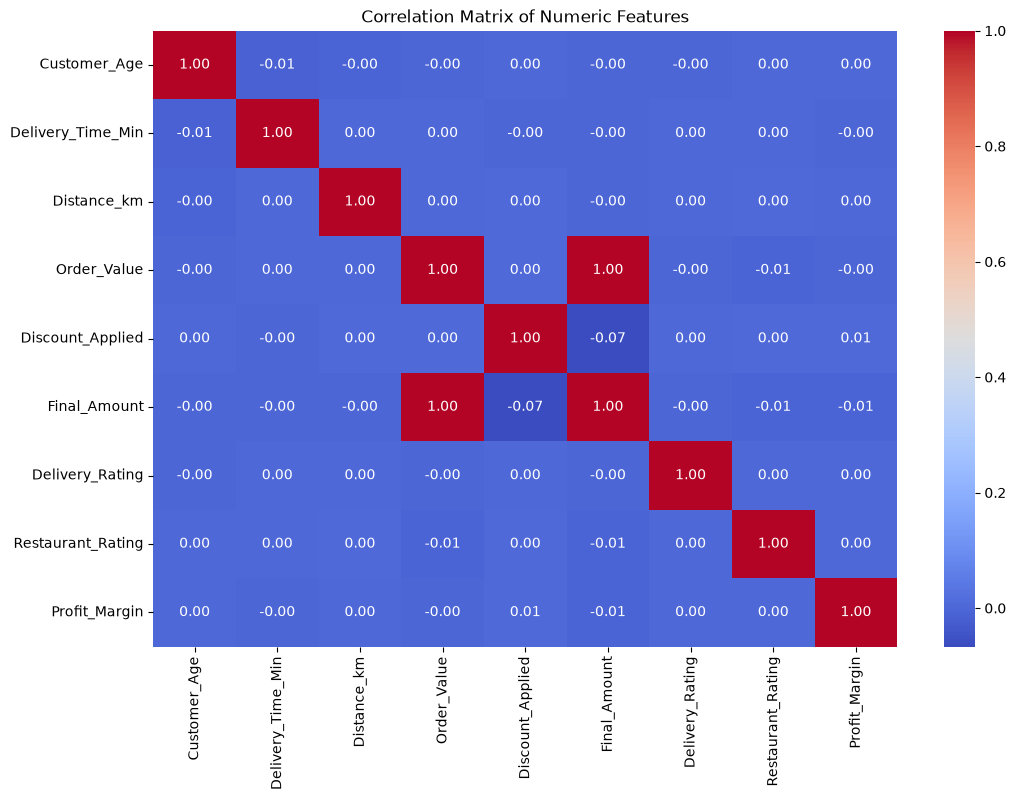

In [87]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numeric Features")
plt.show()

🔹 Step 5: Feature Engineering

5.1 Order Day Type (Weekday / Weekend)
This feature tells us whether an order was placed on a weekday or weekend.

In [88]:
df["Day_Type"] = df["Order_Day"].apply(
    lambda x: "Weekend" if x in ["Saturday", "Sunday"] else "Weekday"
)

print(df[["Order_Day", "Day_Type"]].head(10))

  Order_Day Day_Type
0   Weekend  Weekday
1   Weekday  Weekday
2   Weekend  Weekday
3   Weekday  Weekday
4   Weekend  Weekday
5   Weekday  Weekday
6   Weekday  Weekday
7   Weekend  Weekday
8   Weekend  Weekday
9   Weekday  Weekday


In [89]:
print(df["Day_Type"].value_counts())

Day_Type
Weekday    100000
Name: count, dtype: int64


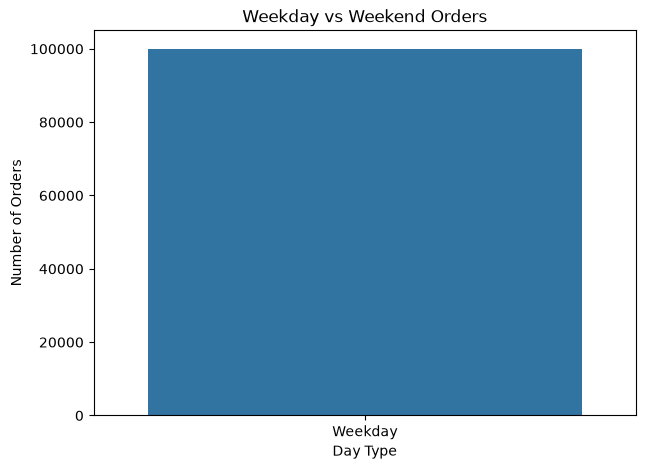

In [90]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Day_Type"
)

plt.title("Weekday vs Weekend Orders")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")
plt.show()

5.2 Peak hour indicator

In [91]:
print(df["Peak_Hour"].unique())

<ArrowStringArray>
['True', nan, 'False']
Length: 3, dtype: str


In [92]:
df["Peak_Hour_Indicator"] = df["Peak_Hour"].map({
    "Yes": 1,
    "No": 0
})

print(df[["Peak_Hour", "Peak_Hour_Indicator"]].head(10))

  Peak_Hour  Peak_Hour_Indicator
0      True                  NaN
1      True                  NaN
2      True                  NaN
3       NaN                  NaN
4     False                  NaN
5      True                  NaN
6       NaN                  NaN
7       NaN                  NaN
8      True                  NaN
9      True                  NaN


In [93]:
print(df["Peak_Hour_Indicator"].value_counts())

Series([], Name: count, dtype: int64)


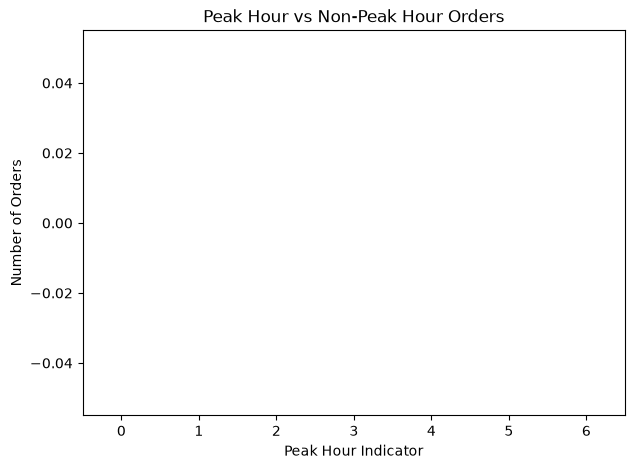

In [94]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Peak_Hour_Indicator"
)

plt.title("Peak Hour vs Non-Peak Hour Orders")
plt.xlabel("Peak Hour Indicator")
plt.ylabel("Number of Orders")
plt.show()

5.3 Profit margin percentage

Profit Margin Percentage tells us what percentage of the order amount is earned as profit.

In [95]:
df["Profit_Margin_Percentage"] = (
    df["Profit_Margin"] / df["Final_Amount"]
) * 100

print(
    df[["Final_Amount", "Profit_Margin", "Profit_Margin_Percentage"]].head(10)
)

   Final_Amount  Profit_Margin  Profit_Margin_Percentage
0           NaN           0.13                       NaN
1        4849.0           0.48                  0.009899
2         737.0           0.08                  0.010855
3           NaN           0.04                       NaN
4         352.0           0.12                  0.034091
5           NaN           0.24                       NaN
6           NaN           0.02                       NaN
7        3486.0           0.18                  0.005164
8         425.0           0.08                  0.018824
9        4641.0           0.03                  0.000646


In [96]:
print(df["Profit_Margin_Percentage"].describe())

count    4.430200e+04
mean              inf
std               NaN
min     -4.500000e+01
25%      0.000000e+00
50%      7.310792e-03
75%      2.464743e-02
max               inf
Name: Profit_Margin_Percentage, dtype: float64


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


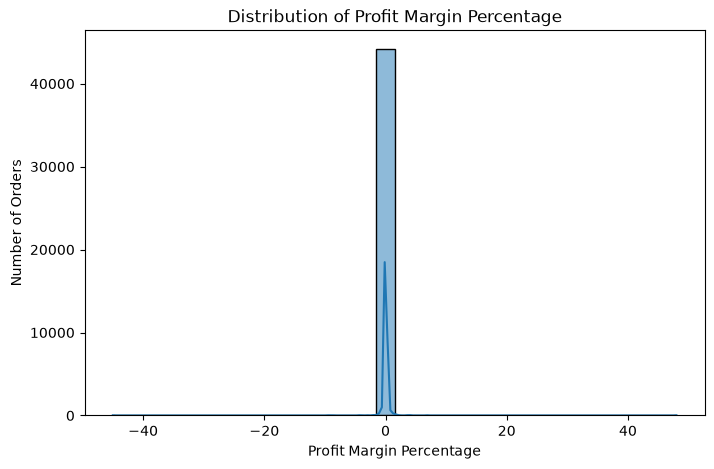

In [97]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Profit_Margin_Percentage"],
    bins=30,
    kde=True
)

plt.title("Distribution of Profit Margin Percentage")
plt.xlabel("Profit Margin Percentage")
plt.ylabel("Number of Orders")
plt.show()

5.4 Delivery performance categories

Delivery Performance Categories
This feature classifies delivery performance based on delivery time.

In [98]:
df["Delivery_Performance"] = pd.cut(
    df["Delivery_Time_Min"],
    bins=[0, 30, 60, float("inf")],
    labels=["Good", "Average", "Poor"]
)

print(df[["Delivery_Time_Min", "Delivery_Performance"]].head(10))

   Delivery_Time_Min Delivery_Performance
0              187.0                 Poor
1               20.0                 Good
2              207.0                 Poor
3              143.0                 Poor
4               51.0              Average
5               56.0              Average
6              273.0                 Poor
7              120.0                 Poor
8              120.0                 Poor
9              120.0                 Poor


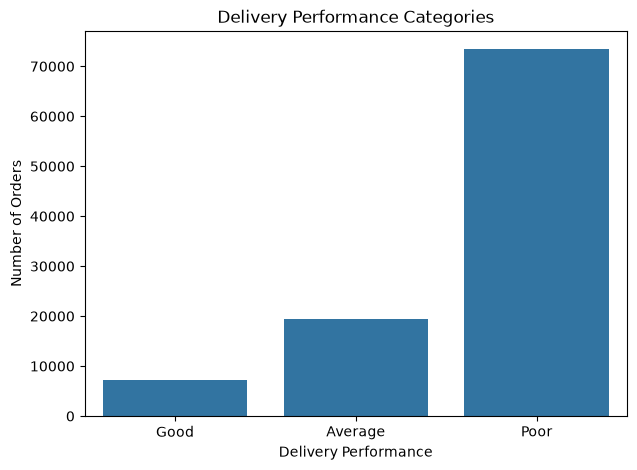

In [99]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Delivery_Performance",
    order=["Good", "Average", "Poor"]
)

plt.title("Delivery Performance Categories")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")
plt.show()

5.6 Customer age groups

In [100]:
df["Age_Group"] = pd.cut(
    df["Customer_Age"],
    bins=[0, 18, 30, 45, 60, 100],
    labels=["Teen", "Young Adult", "Adult", "Middle Age", "Senior"]
)

print(df[["Customer_Age", "Age_Group"]].head(10))

   Customer_Age    Age_Group
0          19.0  Young Adult
1           NaN          NaN
2           NaN          NaN
3           NaN          NaN
4          57.0   Middle Age
5          37.0        Adult
6          40.0        Adult
7           NaN          NaN
8           NaN          NaN
9           NaN          NaN


In [101]:
print(df["Age_Group"].value_counts())

Age_Group
Adult          17445
Middle Age     17386
Young Adult    13919
Teen            1157
Senior             0
Name: count, dtype: int64


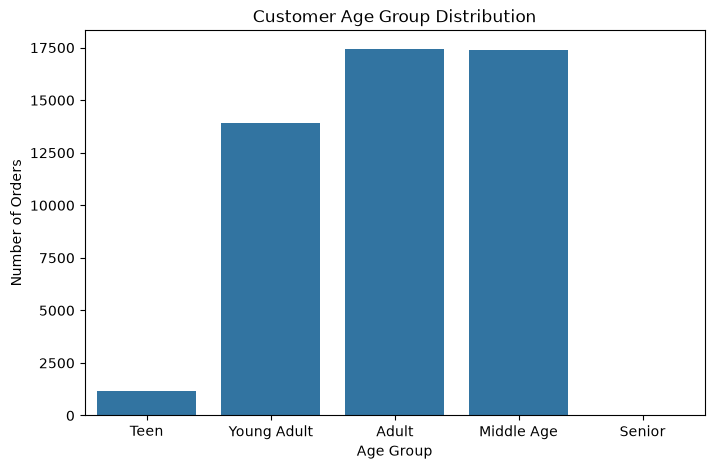

In [102]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Age_Group",
    order=["Teen", "Young Adult", "Adult", "Middle Age", "Senior"]
)

plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of Orders")
plt.show()

🔹 Step 6: Data Storage (MySQL)

6.1 Cleaned data can be stored in MySQL

In [103]:
import pymysql

connection = pymysql.connect(
    host="localhost",
    user="root",
    password="sammathew@12345",
    port=3306
)

cursor = connection.cursor()

print("Connected to MySQL")

Connected to MySQL


In [104]:
cursor.execute("CREATE DATABASE IF NOT EXISTS food_delivery_db")
cursor.execute("USE food_delivery_db")

0

In [105]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS food_orders (
    Order_ID VARCHAR(50),
    Customer_ID VARCHAR(50),
    Customer_Age INT,
    City VARCHAR(100),
    Cuisine_Type VARCHAR(100),
    Order_Date DATE,
    Delivery_Time_Min FLOAT,
    Distance_km FLOAT,
    Order_Value FLOAT,
    Final_Amount FLOAT,
    Order_Status VARCHAR(50),
    Delivery_Rating FLOAT,
    Restaurant_Rating FLOAT,
    Profit_Margin FLOAT,
    Day_Type VARCHAR(20),
    Age_Group VARCHAR(30),
    Delivery_Performance VARCHAR(30),
    Peak_Hour_Indicator INT,
    Profit_Margin_Percentage FLOAT
)
""")

0

In [107]:
insert_query = """
INSERT INTO food_orders (
    Order_ID,
    Customer_ID,
    Customer_Age,
    City,
    Cuisine_Type,
    Order_Date,
    Delivery_Time_Min,
    Distance_km,
    Order_Value,
    Final_Amount,
    Order_Status,
    Delivery_Rating,
    Restaurant_Rating,
    Profit_Margin,
    Day_Type,
    Age_Group,
    Delivery_Performance,
    Peak_Hour_Indicator,
    Profit_Margin_Percentage
)
VALUES (
    %s, %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s
)
"""

In [108]:
columns = [
    "Order_ID",
    "Customer_ID",
    "Customer_Age",
    "City",
    "Cuisine_Type",
    "Order_Date",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Final_Amount",
    "Order_Status",
    "Delivery_Rating",
    "Restaurant_Rating",
    "Profit_Margin",
    "Day_Type",
    "Age_Group",
    "Delivery_Performance",
    "Peak_Hour_Indicator",
    "Profit_Margin_Percentage"
]

data = list(df[columns].itertuples(index=False, name=None))

In [111]:
insert_query

'\nINSERT INTO food_orders (\n    Order_ID,\n    Customer_ID,\n    Customer_Age,\n    City,\n    Cuisine_Type,\n    Order_Date,\n    Delivery_Time_Min,\n    Distance_km,\n    Order_Value,\n    Final_Amount,\n    Order_Status,\n    Delivery_Rating,\n    Restaurant_Rating,\n    Profit_Margin,\n    Day_Type,\n    Age_Group,\n    Delivery_Performance,\n    Peak_Hour_Indicator,\n    Profit_Margin_Percentage\n)\nVALUES (\n    %s, %s, %s, %s, %s, %s, %s, %s, %s,\n    %s, %s, %s, %s, %s, %s, %s, %s, %s, %s\n)\n'

In [112]:
cursor.execute("SELECT COUNT(*) FROM food_orders")

result = cursor.fetchone()

print("Total records:", result[0])

Total records: 0


In [114]:
import pandas as pd

data = [
    tuple(None if pd.isna(value) else value for value in row)
    for row in df[columns].itertuples(index=False, name=None)
]

In [116]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

print(df[columns].dtypes)

Rows: 100000
Columns: 30
Order_ID                         str
Customer_ID                      str
Customer_Age                 float64
City                             str
Cuisine_Type                     str
Order_Date                       str
Delivery_Time_Min            float64
Distance_km                  float64
Order_Value                  float64
Final_Amount                 float64
Order_Status                     str
Delivery_Rating              float64
Restaurant_Rating            float64
Profit_Margin                float64
Day_Type                         str
Age_Group                   category
Delivery_Performance        category
Peak_Hour_Indicator          float64
Profit_Margin_Percentage     float64
dtype: object


In [132]:
print(data[0])

('ORD000001', 'CUST6948', 19.0, None, 'Chinese', datetime.date(2024, 10, 20), 187.0, 15.75, None, None, 'Delivered', 5.0, 4.4, 0.13, 'Weekday', 'Young Adult', 'Poor', None, None)


In [133]:
import pandas as pd
import numpy as np

df_insert = df[columns].copy()

# Convert all NaN and NaT values to None
df_insert = df_insert.replace({np.nan: None})
df_insert = df_insert.astype(object).where(
    pd.notna(df_insert),
    None
)

data = list(
    df_insert.itertuples(index=False, name=None)
)

print(data[0])

('ORD000001', 'CUST6948', 19.0, None, 'Chinese', datetime.date(2024, 10, 20), 187.0, 15.75, None, None, 'Delivered', 5.0, 4.4, 0.13, 'Weekday', 'Young Adult', 'Poor', None, None)


In [134]:
print([
    (i, value)
    for i, value in enumerate(data[0])
    if isinstance(value, float) and np.isnan(value)
])

[]


In [136]:
cursor.execute(insert_query, data[0])
connection.commit()

print("First row inserted successfully")

First row inserted successfully
